# 21. MLOps com exógenas: demanda elétrica real

**Objetivo e requisitos.** Um projeto de operação com dados reais: prever todo dia a demanda elétrica do dia seguinte em Victoria (Austrália) com temperatura, feriado e fim de semana. O fluxo é o do notebook 19, agora com as exógenas guardadas no mesmo banco SQLite: a previsão do tempo e o calendário chegam na véspera, a temperatura observada chega com a demanda. Treino, registro, promoção, operação diária de 2014, monitoramento e retreino com portão. Extras `stats` e `plot`; baixa os dados na primeira execução.

In [1]:
import shutil
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import autohybts
from autohybts import AutoHybridExperiment, ExperimentStore, save_model
from autohybts.datasets import load_exog_dataset

warnings.filterwarnings("ignore")
print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc3


## 1. Dados e protocolo

`vic_elec_daily` agrega a demanda de meia em meia hora de 2012 a 2014 em GWh por dia, com a temperatura máxima, o feriado e o fim de semana. A demanda sobe no frio e no calor, por isso a temperatura entra também ao quadrado.

O conjunto não traz previsões do tempo. Aqui a previsão é **simulada**: a temperatura observada mais um erro normal de desvio 2 °C, valor típico de uma previsão para o dia seguinte. Com isso, cada coluna tem um papel honesto:

- `feriado`, `fim_de_semana`, `temperatura_prevista` (e o quadrado): `future`, conhecidas na véspera;
- `temperatura_max` (e o quadrado): `past`, observada com a demanda e usada com 1 dia de defasagem.

O modelo entra em produção em 1º de janeiro de 2014 e prevê um dia por vez (protocolo B). O portão usa os 60 dias selados de cada treino; o monitoramento usa o MAE móvel de 28 dias contra 1,5 vez a referência; o retreino acontece por alerta (no máximo um a cada 60 dias) ou a cada 120 dias.

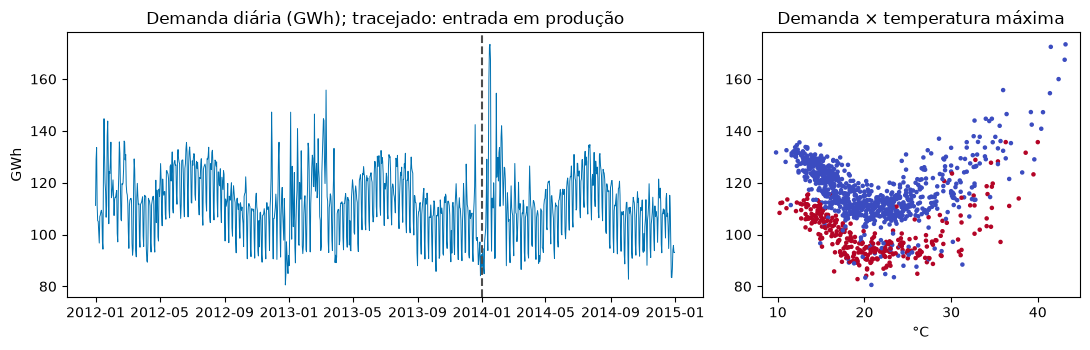

In [2]:
demand, X = load_exog_dataset("vic_elec_daily")
rng = np.random.default_rng(42)
X["temperatura_prevista"] = X["temperatura_max"] + rng.normal(0, 2.0, len(X))
X["temperatura_prevista2"] = X["temperatura_prevista"] ** 2
FUTURE = ["feriado", "fim_de_semana", "temperatura_prevista", "temperatura_prevista2"]
PAST = ["temperatura_max", "temperatura_max2"]
NAME, DEPLOY, GATE, WINDOW, THRESHOLD, SCHEDULE = "demanda_vic", 731, 60, 28, 1.5, 120

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(demand.index, demand.to_numpy(), linewidth=0.7, color="#0072B2")
axes[0].axvline(demand.index[DEPLOY], color="0.3", linestyle="--")
axes[0].set(title="Demanda diária (GWh); tracejado: entrada em produção", ylabel="GWh")
axes[1].scatter(X["temperatura_max"], demand, s=5, c=X["fim_de_semana"], cmap="coolwarm")
axes[1].set(title="Demanda × temperatura máxima", xlabel="°C")
fig.tight_layout()
plt.show()

## 2. Treino, registro e promoção

`train` é o pipeline: experimento com as exógenas (a seleção decide se elas entram), finalização, leitura única do teste selado (o MAE vira a referência), registro do experimento, artefato e modelo. As covariáveis até a entrada em produção vão para a tabela `covariates` do banco: é dela que o serviço lê o que precisa.

In [3]:
folder = Path("artifacts/mlops_energia")
shutil.rmtree(folder, ignore_errors=True)
store = ExperimentStore(folder / "energia.db")
SERIES = "__single__"
SETTINGS = {
    "fh": 1,
    "variant": "B",
    "test_size": GATE,
    "session_id": 42,
    "budget": "small",
    "base_models": ["seasonal_naive", "linear", "knn"],
    "correctors": ["linear"],
    "exog_future": FUTURE,
}


def train(t, label):
    exp = AutoHybridExperiment(**SETTINGS).fit(demand.iloc[:t], X.iloc[:t])
    result = exp.compare_models()
    final = exp.finalize_model(result.best)
    mae = float(exp.evaluate_external(final).metrics["MAE"].iloc[0])
    run_id = store.log(exp, name=label, models=[final], values=True)
    path = save_model(final, folder / "modelos" / final.model_id[:12])
    store.register_model(final, path, name=NAME, run_id=run_id, reference_mae=mae)
    return final, mae, run_id


store.log_covariates(SERIES, X.iloc[:DEPLOY])
first, reference, _ = train(DEPLOY, "treino-inicial")
store.promote(first.model_id, reason="primeiro modelo")
store.query(
    """
    SELECT d.family, d.challenger_label AS desafiante, d.accepted AS aceito,
           ROUND(d.median_gain, 3) AS ganho_mediano
    FROM decisions d JOIN runs r USING (run_id) WHERE r.name = 'treino-inicial'
    """
)

,family,desafiante,aceito,ganho_mediano
0,statistical,seasonal_naive(season_length=7),0,-0.871
1,linear,linear(lags=7),0,-0.694
2,residual,"knn(lags=7) + linear [w=7, alpha=0.5, historic...",0,0.290
3,exogenous,"knn(lags=7) + linear [w=7, alpha=1.0, historic...",1,0.510


## 3. Operação diária

Na véspera chegam a previsão do tempo e o calendário: vão para o banco e para `predict_next`. No dia seguinte chegam a demanda e a temperatura observada: vão para o banco e para `observe`. O serviço carrega o modelo de produção pelo registro e o atualiza, sem reajuste, com as observações e as covariáveis lidas da tabela `covariates`.

In [4]:
def serve(t):
    """Production model from the registry, updated up to day t with the stored covariates."""
    model = store.load(NAME, trusted=True)
    start = demand.index.get_loc(model.last_observation) + 1
    if start > t:
        return model.stream()
    covariates = store.covariates(SERIES, demand.index[start], demand.index[t])
    return model.update_state(demand.iloc[start : t + 1], X_new=covariates).stream()


stream, events, last_retrain = serve(DEPLOY - 1), [], DEPLOY
for t in range(DEPLOY, len(demand)):
    day = demand.index[t]
    ahead = X.loc[[day], FUTURE]  # known the day before
    store.log_covariates(SERIES, ahead)
    ticket = stream.predict_next(ahead)
    model_id = stream.model.model_id
    store.log_forecasts(
        model_id,
        pd.DataFrame(
            {
                "timestamp": [ticket.timestamp],
                "origin": [ticket.origin],
                "y_pred": [ticket.prediction],
            }
        ),
    )
    observed = X.loc[[day], PAST]  # arrives with the demand
    stream.observe(float(demand.iloc[t]), observed)
    store.log_covariates(SERIES, observed)
    store.log_actuals(SERIES, demand.iloc[t : t + 1])
    alert = bool(store.monitor(model_id, window=WINDOW, threshold=THRESHOLD).alert.iloc[-1])
    if not ((alert and t - last_retrain >= GATE) or t - last_retrain >= SCHEDULE):
        continue
    reason = "alerta" if alert else "agenda"
    challenger, challenger_mae, run_id = train(t + 1, f"retreino-{day.date()}")
    live_mae = store.query(
        """
        SELECT AVG(ABS(a.y_true - f.y_pred)) AS mae
        FROM forecasts f JOIN actuals a USING (series_id, timestamp)
        WHERE f.model_id = ? AND f.timestamp IN (SELECT timestamp FROM predictions WHERE run_id = ?)
        """,
        (model_id, run_id),
    ).mae[0]
    promoted = challenger_mae <= live_mae
    if promoted:
        store.promote(
            challenger.model_id, reason=f"{reason}: MAE {challenger_mae:.2f} <= {live_mae:.2f}"
        )
        stream = serve(t)
    events.append(
        {
            "dia": day.date(),
            "motivo": reason,
            "desafiante": challenger.spec.label,
            "mae_desafiante": round(challenger_mae, 2),
            "mae_producao": round(live_mae, 2),
            "promovido": promoted,
        }
    )
    last_retrain = t
pd.DataFrame(events)

,dia,motivo,desafiante,mae_desafiante,mae_producao,promovido
0,2014-03-02,alerta,linear(lags=7),11.72,7.39,False
1,2014-06-30,agenda,"knn(lags=7) | exog: feriado, fim_de_semana, te...",2.51,2.37,False
2,2014-10-28,agenda,knn(lags=7),2.78,2.47,False


## 4. Monitoramento

O histórico de estágios e o erro real de cada modelo no período em que esteve em produção, contra a sua referência.

In [5]:
store.query(
    """
    SELECT r.label, MIN(f.timestamp) AS inicio, MAX(f.timestamp) AS fim, COUNT(*) AS dias,
           ROUND(AVG(ABS(a.y_true - f.y_pred)), 2) AS mae_real,
           ROUND(r.reference_mae, 2) AS mae_referencia
    FROM forecasts f
    JOIN actuals a USING (series_id, timestamp)
    JOIN registry r USING (model_id)
    GROUP BY f.model_id ORDER BY inicio
    """
)

,label,inicio,fim,dias,mae_real,mae_referencia
0,"knn(lags=7) + linear [w=7, alpha=1.0, historic...",2014-01-01T00:00:00,2014-12-31T00:00:00,365,3.47,3.12


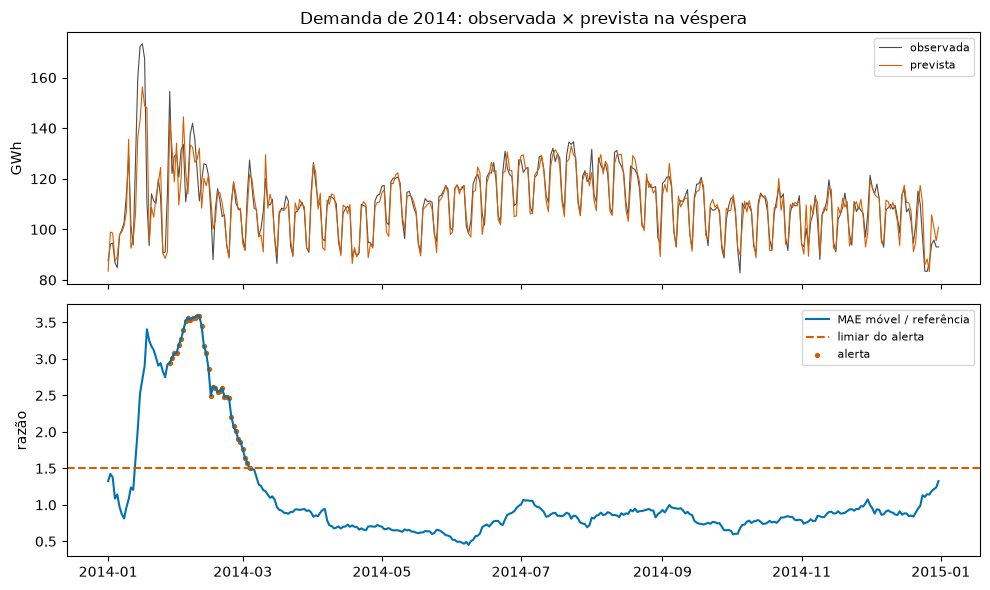

In [6]:
status = pd.concat(
    [
        store.monitor(m, window=WINDOW, threshold=THRESHOLD)
        for m in store.query("SELECT DISTINCT model_id FROM forecasts").model_id
    ]
).sort_values("timestamp")
status["timestamp"] = pd.to_datetime(status.timestamp)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(status.timestamp, status.y_true, color="0.3", linewidth=0.8, label="observada")
axes[0].plot(status.timestamp, status.y_pred, color="#D55E00", linewidth=0.8, label="prevista")
axes[0].set(ylabel="GWh", title="Demanda de 2014: observada × prevista na véspera")
axes[0].legend(fontsize=8)
axes[1].plot(status.timestamp, status.ratio, color="#0072B2", label="MAE móvel / referência")
axes[1].axhline(THRESHOLD, color="#D55E00", linestyle="--", label="limiar do alerta")
alerts = status[status.alert]
axes[1].scatter(alerts.timestamp, alerts.ratio, s=8, color="#D55E00", label="alerta")
axes[1].set(ylabel="razão")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 5. Avaliação da operação

As previsões usadas contra duas referências calculadas no próprio banco: a persistência (o dia anterior, `LAG(1)`) e a persistência semanal (o mesmo dia da semana anterior, `LAG(7)`). Por trimestre, para ver se o ganho se mantém nas estações.

In [7]:
quarters = store.query(
    """
    WITH o AS (
        SELECT timestamp, y_true,
               LAG(y_true, 1) OVER (ORDER BY timestamp) AS ontem,
               LAG(y_true, 7) OVER (ORDER BY timestamp) AS semana
        FROM actuals
    )
    SELECT 'T' || ((CAST(strftime('%m', o.timestamp) AS INTEGER) + 2) / 3) AS trimestre,
           COUNT(*) AS dias,
           ROUND(AVG(ABS(o.y_true - f.y_pred)), 2) AS mae_operacao,
           ROUND(AVG(ABS(o.y_true - o.ontem)), 2) AS mae_persistencia,
           ROUND(AVG(ABS(o.y_true - o.semana)), 2) AS mae_semanal
    FROM forecasts f JOIN o USING (timestamp)
    WHERE o.semana IS NOT NULL
    GROUP BY trimestre ORDER BY trimestre
    """
)
quarters

,trimestre,dias,mae_operacao,mae_persistencia,mae_semanal
0,T1,83,6.17,10.92,14.62
1,T2,91,2.33,6.26,5.19
2,T3,92,2.48,6.85,4.69
3,T4,92,3.19,6.80,5.45


In [8]:
store.query(
    """
    SELECT ROUND(AVG(ABS(p.value - o.value)), 2) AS erro_medio_previsao_temperatura,
           COUNT(*) AS dias
    FROM covariates p
    JOIN covariates o ON o.series_id = p.series_id AND o.timestamp = p.timestamp
    WHERE p.column = 'temperatura_prevista' AND o.column = 'temperatura_max'
      AND p.timestamp >= ?
    """,
    (demand.index[DEPLOY].isoformat(),),
)

,erro_medio_previsao_temperatura,dias
0,1.51,365


## 6. Leitura

- **Treino inicial.** Com dois anos de histórico, a família `exogenous` foi aceita com ganho mediano de 51 % sobre o campeão univariado. O modelo de produção é um KNN sobre 7 lags com corretor linear, que usa a previsão do tempo, o feriado, o fim de semana e a temperatura do dia anterior. A correção residual sem exógenas tinha ganho de 29 %, mas não passou na regra de aceite.
- **Operação de 2014.** O mesmo modelo ficou em produção os 365 dias, com MAE real de 3,47 GWh contra a referência de 3,12 do teste selado. Houve três retreinos: um por alerta, em 2 de março, depois do calor do verão australiano, e dois por agenda. Nenhum desafiante passou no portão. O desafiante do alerta, treinado sem exógenas (a seleção as recusou naquele treino), teve MAE de 11,72 nos 60 dias selados, contra 7,39 da produção real nas mesmas datas.
- **Contra as referências.** A operação venceu as duas persistências em todos os trimestres. No primeiro trimestre, o mais difícil por causa das ondas de calor, o MAE foi 6,17 GWh, contra 10,92 do dia anterior e 14,62 da semana anterior. Nos outros trimestres ficou entre 2,3 e 3,2, menos da metade da persistência.
- **Entradas auditáveis.** A tabela `covariates` guarda o que o modelo recebeu na véspera e o que foi observado depois. Uma consulta mostra o erro médio da previsão do tempo usada: 1,51 °C. Aqui a previsão é simulada; com uma previsão real, basta registrar a coluna e repetir a consulta.
- **O que o banco permite.** O serviço reconstrói o modelo de produção a partir do registro e das covariáveis guardadas. Cada decisão (treino, portão, alerta) fica rastreável com SQL.